# MPIIGaze 탐색적 데이터 분석 (EDA)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/paragon0730/gaze_estimation/blob/main/eda.ipynb)

전처리된 MPIIGaze eye-based 데이터(`data/EyeBased/MPIIGaze`, 15명 × 3,000개)를 살펴보고, 모델·평가 설계에 쓸 사실을 정리함.

- 입력: 36×60 grayscale 눈 이미지 + head pose `2DHead` (yaw, pitch)
- 정답: `2DGaze` (yaw, pitch), 라디안. 이 노트북에서는 읽기 쉽게 **도(°)** 로 바꿔 보여 줌
- 평가: leave-one-person-out → **사람 사이의 차이**를 중점적으로 봄

목차
1. 데이터 구성 (샘플 수, 눈, day, 중복)
2. 원본 대비 규모
3. 이미지 (예시, 밝기, 사람별 평균 얼굴)
4. 라벨 분포 (gaze, head pose)
5. 사람별 분포 차이
6. 왼눈 vs 오른눈
7. gaze와 head pose의 관계
8. 카메라–눈 거리
9. 이미지와 gaze의 관계
10. 단순 기준선: 평균 gaze 예측
11. 정리

In [1]:
# Colab에서 열었을 때만: 저장소를 받고 데이터를 내려받아 전처리 (약 2GB, 수십 분)
def is_colab():
    try:
        import google.colab  # noqa
        return True
    except ImportError:
        return False

if is_colab():
    !git clone https://github.com/paragon0730/gaze_estimation.git
    %cd gaze_estimation
    !pip -q install opencv-python scipy
    !apt-get -qq install -y fonts-nanum > /dev/null   # 그림의 한글 표시용
    !python -m preprocess.mpii

In [2]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gaze import viz
from gaze.data import DATA_ROOT, PERSONS, load_all, raw_frame_counts, read_label_table
from gaze.metrics import angular_error

viz.setup()
pd.set_option("display.precision", 2)
assert os.path.isdir(os.path.join(DATA_ROOT, "Label")), "먼저 python -m preprocess.mpii 를 실행한다."

## 1. 데이터 구성

라벨 파일의 모든 칸을 하나의 표로 읽음. 각도는 도(°)로 바꿈.

In [3]:
def vec(col, i):
    return np.array([float(v.split(",")[i]) for v in col])

frames = []
for p in PERSONS:
    t = read_label_table(DATA_ROOT, p)
    day, frame = zip(*[o.split("/") for o in t["Origin"]])
    frames.append(pd.DataFrame({
        "person": p, "image": t["Image"], "origin": t["Origin"], "day": day, "frame": frame,
        "eye": t["WhichEye"],
        "gaze_yaw": np.degrees(vec(t["2DGaze"], 0)), "gaze_pitch": np.degrees(vec(t["2DGaze"], 1)),
        "head_yaw": np.degrees(vec(t["2DHead"], 0)), "head_pitch": np.degrees(vec(t["2DHead"], 1)),
        "distance_mm": 600.0 / vec(t["Smat"], 2),   # Smat = (1, 1, 600/d)
    }))
df = pd.concat(frames, ignore_index=True)
print(df.shape)
df.head()

(45000, 11)


,person,image,origin,day,frame,eye,gaze_yaw,gaze_pitch,head_yaw,head_pitch,distance_mm
0,p00,p00/1.jpg,day08/0069.jpg,day08,0069.jpg,left,14.17,-2.99,-6.57,29.08,498.05
1,p00,p00/2.jpg,day28/0646.jpg,day28,0646.jpg,left,4.37,-13.17,0.95,7.36,446.63
2,p00,p00/3.jpg,day04/0900.jpg,day04,0900.jpg,left,10.03,-1.75,-18.02,5.50,467.57
3,p00,p00/4.jpg,day12/0440.jpg,day12,0440.jpg,left,1.45,-10.25,-0.69,4.23,464.04
4,p00,p00/5.jpg,day35/0247.jpg,day35,0247.jpg,left,9.31,-3.32,8.20,6.13,387.67


In [4]:
summary = df.groupby("person").agg(
    samples=("image", "size"),
    left=("eye", lambda s: (s == "left").sum()),
    right=("eye", lambda s: (s == "right").sum()),
    days=("day", "nunique"),
    unique_frames=("origin", "nunique"),
)
summary["dup_(frame,eye)"] = df.groupby("person").apply(
    lambda g: g.duplicated(["origin", "eye"]).sum(), include_groups=False)
print("전체 샘플:", len(df), "/ 결측값:", int(df.isna().sum().sum()))
summary.T

전체 샘플: 45000 / 결측값: 0


person,p00,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p12,p13,p14
samples,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000
left,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500
right,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500
days,39,67,39,65,25,38,62,56,47,20,16,19,7,12,7
unique_frames,2927,2904,2916,2929,2860,2870,2877,2843,2767,2719,2194,2262,1601,1498,1500
"dup_(frame,eye)",0,0,0,0,0,0,0,0,0,0,0,0,0,4,0


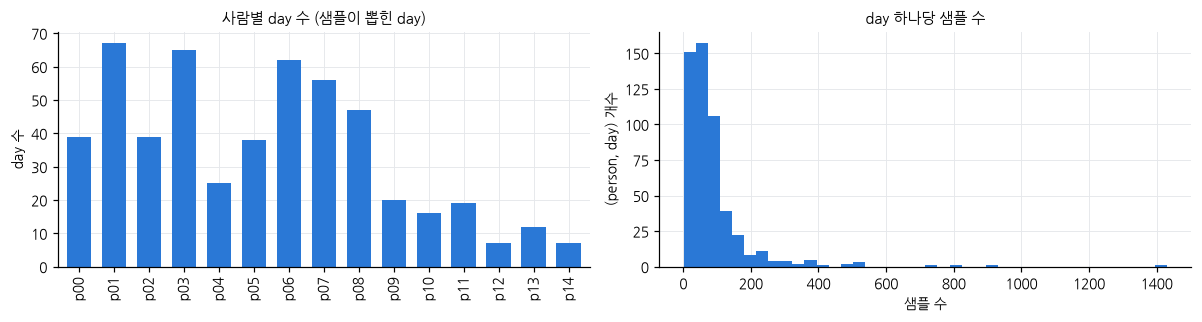

{'count': 519.0, 'mean': 86.7, 'std': 113.2, 'min': 1.0, '25%': 32.0, '50%': 60.0, '75%': 98.0, 'max': 1431.0}


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
per_day = df.groupby(["person", "day"]).size()
summary["days"].plot.bar(ax=axes[0], color=viz.BLUE, width=0.7)
axes[0].set(title="사람별 day 수 (샘플이 뽑힌 day)", xlabel="", ylabel="day 수")
axes[1].hist(per_day.values, bins=40, color=viz.BLUE)
axes[1].set(title="day 하나당 샘플 수", xlabel="샘플 수", ylabel="(person, day) 개수")
plt.tight_layout(); plt.show()
print(per_day.describe().round(1).to_dict())

## 2. 원본 대비 규모

원본 `Data/Original`의 전체 프레임 중 Evaluation Subset(사람당 1,500 프레임 × 양쪽 눈)만 학습에 씀. 원본이 있을 때만 계산함 (GitHub Actions에서는 전처리 단계에서 `data/raw_stats.json`으로 저장해 둠).

In [6]:
raw = None
if os.path.isdir("data/MPIIGaze/Data/Original"):
    raw = raw_frame_counts("data/MPIIGaze")
elif os.path.exists("data/raw_stats.json"):
    raw = json.load(open("data/raw_stats.json"))

if raw:
    raw_df = pd.DataFrame({
        "raw_days": {p: len(d) for p, d in raw.items()},
        "raw_frames": {p: sum(d.values()) for p, d in raw.items()},
    })
    raw_df["used_frames"] = summary["unique_frames"]
    raw_df["used_%"] = 100 * raw_df["used_frames"] / raw_df["raw_frames"]
    print("원본 전체 프레임:", raw_df["raw_frames"].sum())
    display(raw_df.T)
else:
    print("원본 데이터가 없어 건너뜀")

원본 전체 프레임: 213658


,p00,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p12,p13,p14
raw_days,39.00,69.00,39.00,65.00,25.00,38.00,62.0,56.00,47.00,20.00,16.00,19.00,7.0,12.0,7.0
raw_frames,29961.00,24143.00,28019.00,35075.00,16831.00,16577.00,18448.0,15509.00,10701.00,7995.00,2810.00,2982.00,1609.0,1498.0,1500.0
used_frames,2927.00,2904.00,2916.00,2929.00,2860.00,2870.00,2877.0,2843.00,2767.00,2719.00,2194.00,2262.00,1601.0,1498.0,1500.0
used_%,9.77,12.03,10.41,8.35,16.99,17.31,15.6,18.33,25.86,34.01,78.08,75.86,99.5,100.0,100.0


## 3. 이미지

### 3.1 예시

행 = 사람, 열 = 무작위 샘플. 오른눈(R)은 전처리에서 좌우 반전되어 왼눈처럼 보임.

loaded cache data/mpiigaze_eye.npz: 45000 samples


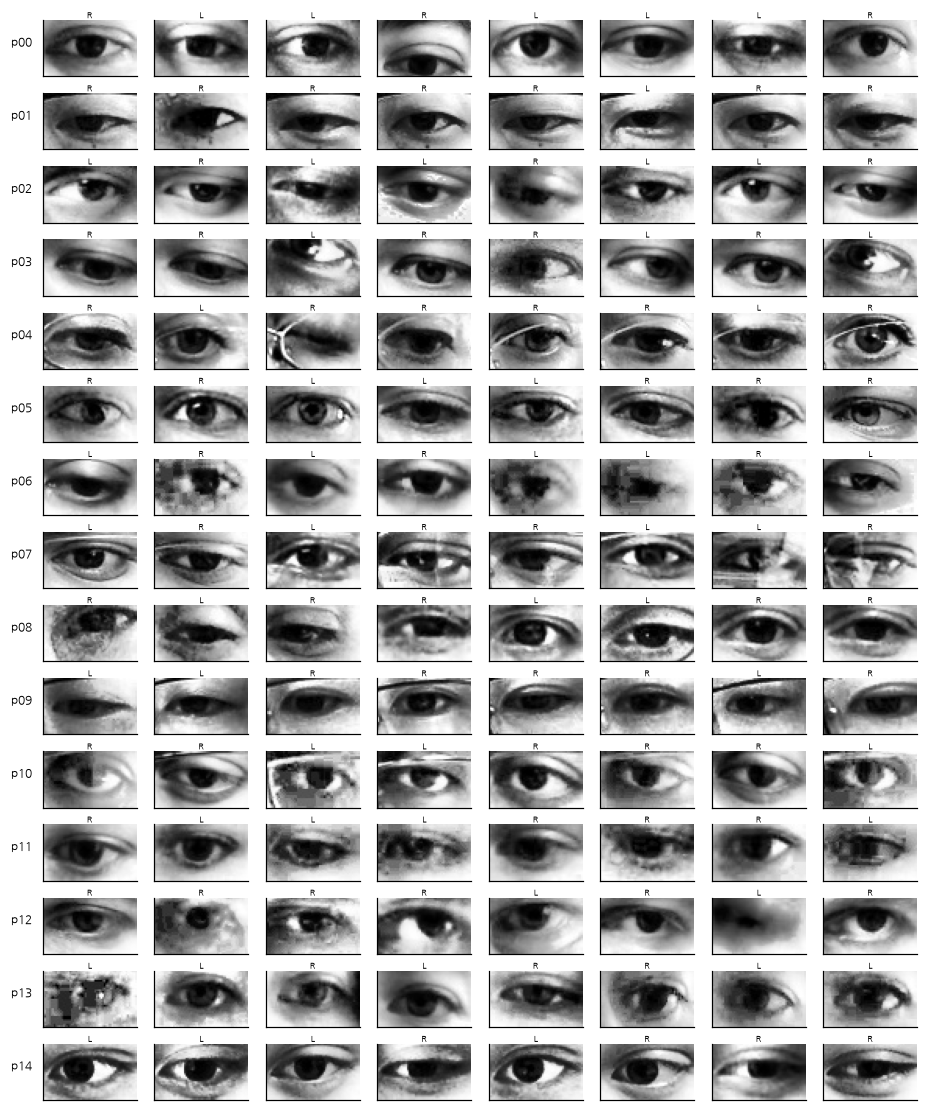

In [7]:
data = load_all()   # {person: (eye uint8 (N,36,60), head (N,2), gaze (N,2))}, data/mpiigaze_eye.npz 캐시
eye_of = {p: df.loc[df.person == p, "eye"].values for p in PERSONS}  # 이미지 순서 = 라벨 순서
rng = np.random.default_rng(0)
cols = 8
fig, axes = plt.subplots(len(PERSONS), cols, figsize=(cols * 1.3, len(PERSONS) * 0.85))
for r, p in enumerate(PERSONS):
    idx = rng.choice(len(data[p][0]), cols, replace=False)
    for c, i in enumerate(idx):
        ax = axes[r, c]
        ax.imshow(data[p][0][i], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title("L" if eye_of[p][i] == "left" else "R", fontsize=6, pad=1)
    axes[r, 0].set_ylabel(p, rotation=0, labelpad=14, fontsize=8)
plt.subplots_adjust(wspace=0.05, hspace=0.3); plt.show()

### 3.2 gaze 화살표

`read_sample.ipynb`와 같은 방식으로 gaze(초록)와 head pose(주황) 방향을 겹쳐 그림.

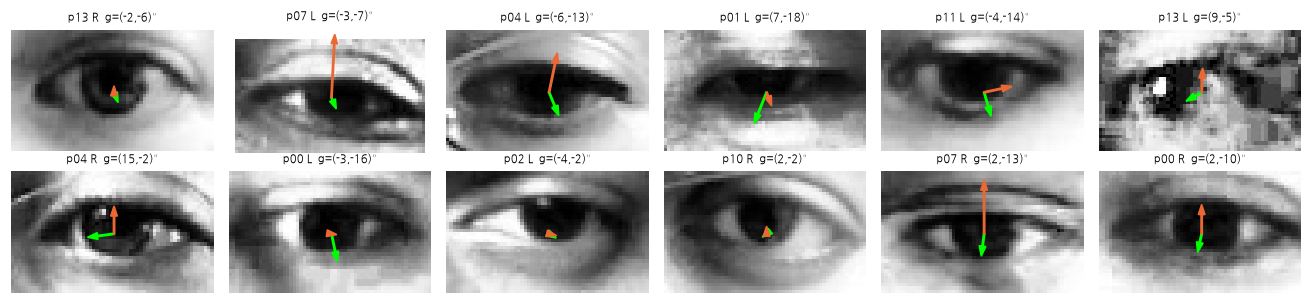

In [8]:
fig, axes = plt.subplots(2, 6, figsize=(12, 2.8))
for ax, i in zip(axes.ravel(), rng.choice(len(df), 12, replace=False)):
    p, j = df.person[i], int(df.image[i].split("/")[1].split(".")[0]) - 1
    img = data[p][0][j] / 255.0
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    viz.draw_gaze(ax, img, data[p][2][j], "lime")
    viz.draw_gaze(ax, img, data[p][1][j], viz.ORANGE)
    ax.set_title(f"{p} {df.eye[i][0].upper()}  g=({df.gaze_yaw[i]:.0f},{df.gaze_pitch[i]:.0f})°", fontsize=7)
    ax.axis("off")
plt.tight_layout(); plt.show()

### 3.3 밝기

전처리에서 histogram equalization을 했으므로 픽셀 값은 0~255에 고르게 퍼져야 함. 사람별 평균 밝기·대비(표준편차)도 비교함.

픽셀 전체 평균 129.2, 표준편차 73.9 (0~255)


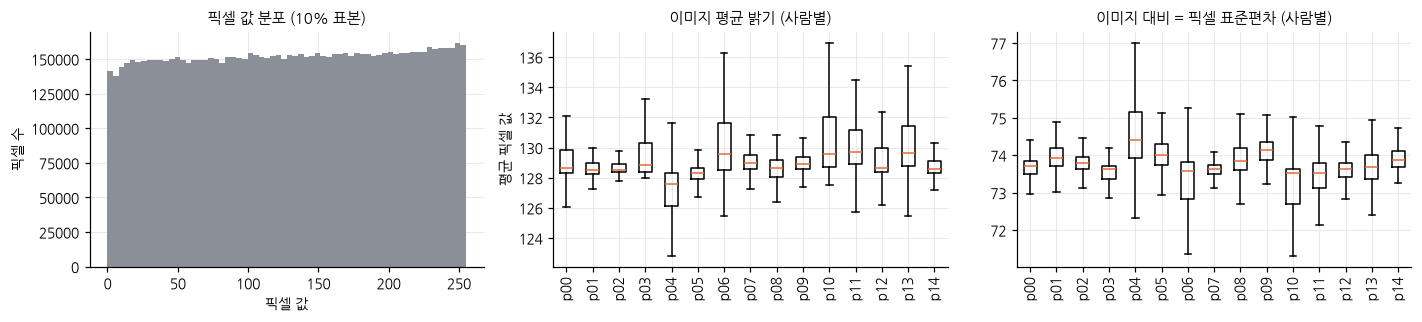

In [9]:
all_eye = np.concatenate([data[p][0] for p in PERSONS])
img_mean = all_eye.reshape(len(all_eye), -1).mean(1)
img_std = all_eye.reshape(len(all_eye), -1).std(1)
print(f"픽셀 전체 평균 {all_eye.mean():.1f}, 표준편차 {all_eye.std():.1f} (0~255)")

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
axes[0].hist(all_eye[::10].ravel(), bins=64, color=viz.GRAY)
axes[0].set(title="픽셀 값 분포 (10% 표본)", xlabel="픽셀 값", ylabel="픽셀 수")
groups = np.split(img_mean, len(PERSONS))
axes[1].boxplot(groups, tick_labels=PERSONS, showfliers=False)
axes[1].set(title="이미지 평균 밝기 (사람별)", ylabel="평균 픽셀 값"); axes[1].tick_params(axis="x", rotation=90)
axes[2].boxplot(np.split(img_std, len(PERSONS)), tick_labels=PERSONS, showfliers=False)
axes[2].set(title="이미지 대비 = 픽셀 표준편차 (사람별)"); axes[2].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

### 3.4 평균 이미지

전체 평균·표준편차 이미지와 사람별 평균 이미지. 사람마다 눈 모양·안경·조명이 달라 평균 얼굴이 다름 → 사람 단위 일반화가 어려운 이유.

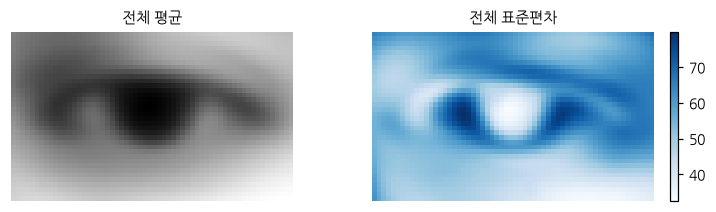

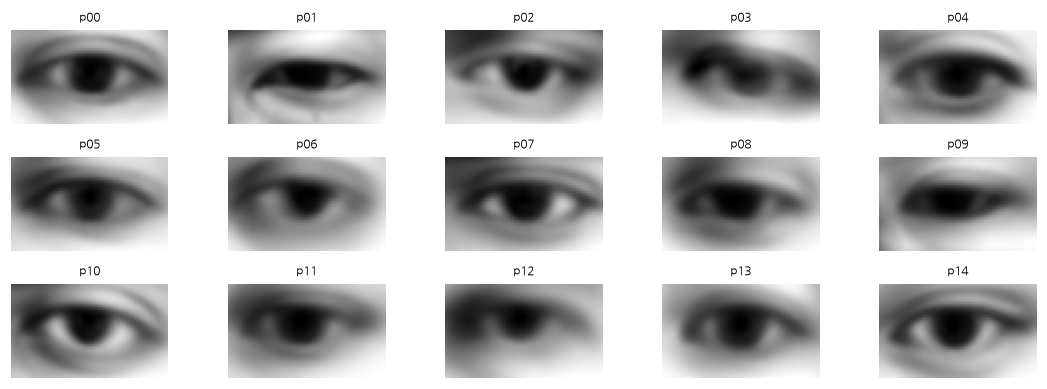

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(8, 2))
axes[0].imshow(all_eye.mean(0), cmap="gray"); axes[0].set_title("전체 평균")
im = axes[1].imshow(all_eye.std(0), cmap="Blues"); axes[1].set_title("전체 표준편차")
plt.colorbar(im, ax=axes[1], fraction=0.03)
for ax in axes: ax.axis("off")
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(10, 3.6))
for ax, p in zip(axes.ravel(), PERSONS):
    ax.imshow(data[p][0].mean(0), cmap="gray"); ax.set_title(p, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. 라벨 분포

### 4.1 요약 통계 (도)

In [11]:
cols4 = ["gaze_yaw", "gaze_pitch", "head_yaw", "head_pitch"]
df[cols4].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
gaze_yaw,45000.0,0.03,8.69,-41.53,-16.68,-7.20,1.28e-01,7.24e+00,16.64,38.72
gaze_pitch,45000.0,-8.75,5.20,-22.76,-18.49,-13.07,-8.78e+00,-4.38e+00,1.03,4.76
head_yaw,45000.0,-0.97,8.35,-51.23,-25.78,-3.21,-2.59e-15,5.17e-15,22.42,46.81
head_pitch,45000.0,9.75,13.45,-45.33,-24.20,1.48,6.05e+00,1.85e+01,44.71,55.94


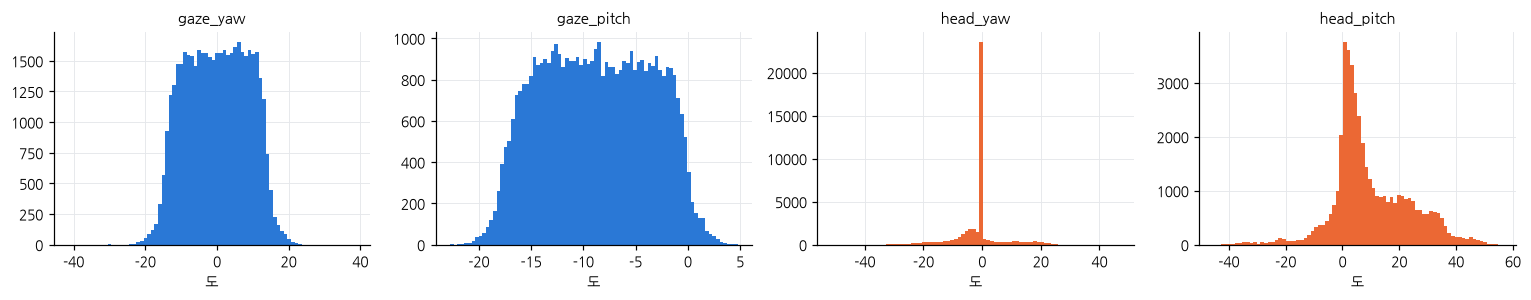

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(14, 2.8))
for ax, c, color in zip(axes, cols4, [viz.BLUE, viz.BLUE, viz.ORANGE, viz.ORANGE]):
    ax.hist(df[c], bins=80, color=color)
    ax.set(title=c, xlabel="도")
plt.tight_layout(); plt.show()

### 4.2 2D 분포

gaze와 head pose의 (yaw, pitch) 평면 분포. 화면 안을 보는 데이터라 gaze 범위가 좁고 한쪽으로 치우쳐 있음.

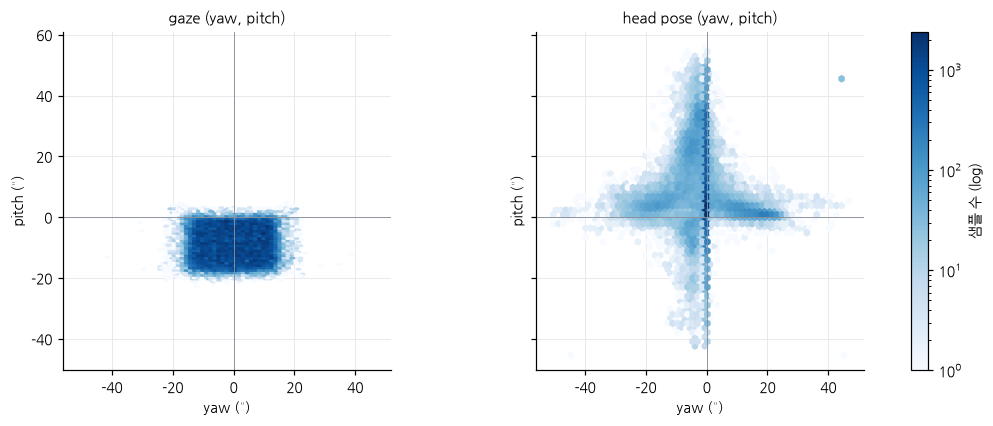

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, (y, p), title in zip(axes, [("gaze_yaw", "gaze_pitch"), ("head_yaw", "head_pitch")], ["gaze", "head pose"]):
    hb = ax.hexbin(df[y], df[p], gridsize=60, cmap="Blues", mincnt=1, bins="log")
    ax.set(title=f"{title} (yaw, pitch)", xlabel="yaw (°)", ylabel="pitch (°)")
    ax.axhline(0, color=viz.GRAY, lw=0.6); ax.axvline(0, color=viz.GRAY, lw=0.6)
    ax.set_aspect("equal")
plt.colorbar(hb, ax=axes, label="샘플 수 (log)", fraction=0.025)
plt.show()

## 5. 사람별 분포 차이

leave-one-person-out에서는 학습에 없던 사람을 맞혀야 함. 사람마다 gaze·head 분포가 얼마나 다른지 확인함.

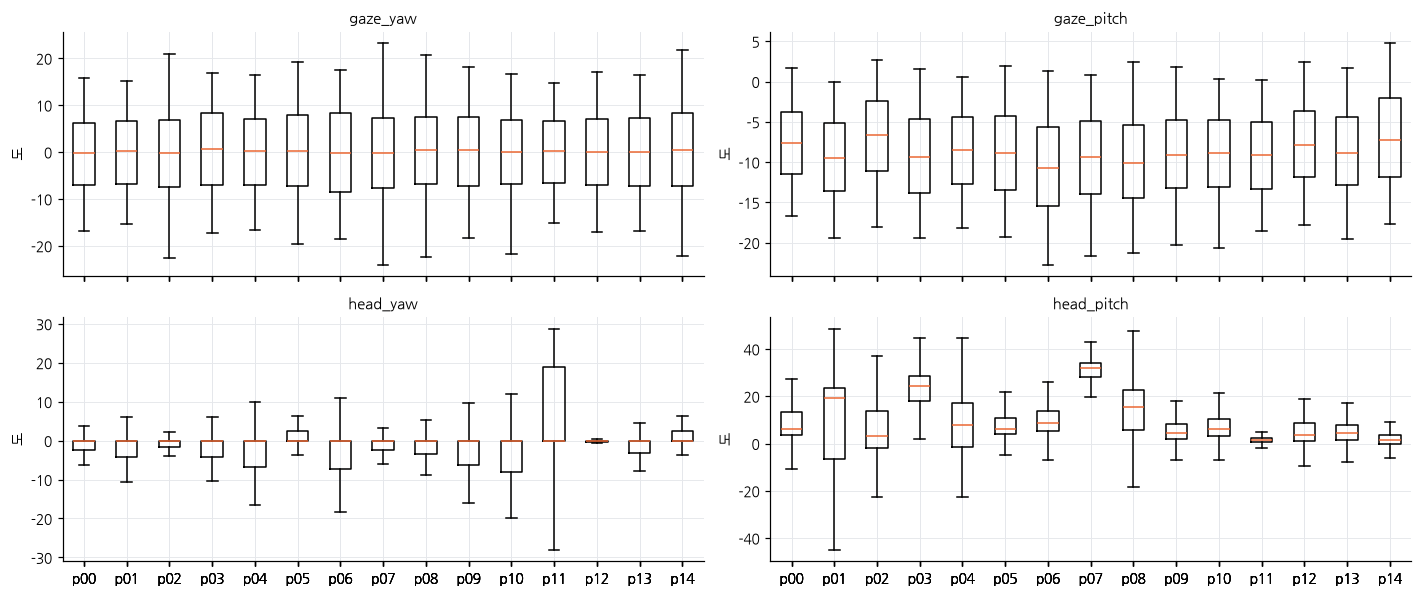

gaze_yaw        gaze_pitch       head_yaw        head_pitch       
            mean    std       mean   std     mean    std       mean    std
person                                                                    
p00    -3.74e-01   7.98      -7.61  4.57    -0.93   5.53       9.44   9.72
p01    -4.37e-02   8.01      -9.49  4.88    -2.06   4.11      11.10  15.27
p02    -1.88e-01   8.17      -6.79  4.96    -0.98   3.45       5.96   9.55
p03     4.76e-01   8.89      -9.23  5.42    -1.91   3.84      19.36  14.68
p04     6.87e-03   8.44      -8.57  5.02    -3.20   6.18       8.17  10.86
p05     2.66e-01   9.31      -8.87  5.29     0.64   9.52       8.47   7.33
p06    -2.39e-01   9.52     -10.50  5.68    -3.60   7.63      10.04  10.02
p07    -2.48e-01   9.13      -9.49  5.21    -1.36   2.72      25.38  17.65
p08     2.63e-01   9.07      -9.97  5.35    -1.51   7.20      14.62  13.16
p09     1.91e-01   8.41      -9.08  4.97    -2.16   9.76       7.02  12.36
p10    -4.09e-02   8.14      -8.97  4.87    -3.78   7.89       7.11   6.70
p11     6.42e-02   7.81      -9.10  4.80     7.07  11.28       3.27  12.04
p12    -1.20e-02   7.96      -7.83  4.83     0.54  10.98       6.63  13.33
p13    -1.47e-02   8.54      -8.70  4.88    -1.54  12.39       7.95  13.23
p14     3.91e-01  10.47      -7.01  5.62     0.26   8.51       1.72  10.59

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 5.5), sharex=True)
for ax, c in zip(axes.ravel(), cols4):
    ax.boxplot([df.loc[df.person == p, c] for p in PERSONS], tick_labels=PERSONS, showfliers=False,
               medianprops={"color": viz.ORANGE})
    ax.set(title=c, ylabel="도")
plt.tight_layout(); plt.show()

per_person = df.groupby("person")[cols4].agg(["mean", "std"])
per_person

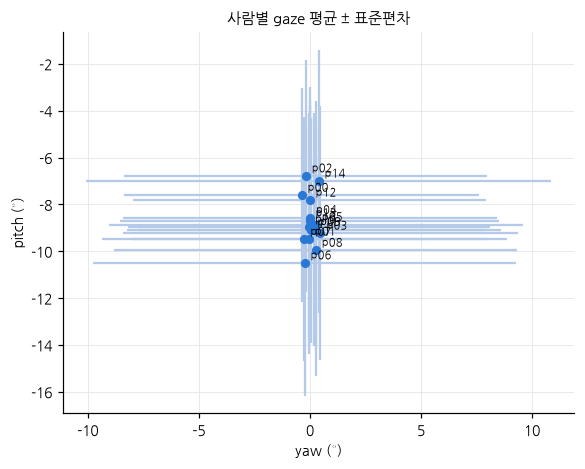

In [15]:
fig, ax = plt.subplots(figsize=(6, 4.5))
m = df.groupby("person")[["gaze_yaw", "gaze_pitch"]].mean()
s = df.groupby("person")[["gaze_yaw", "gaze_pitch"]].std()
ax.errorbar(m.gaze_yaw, m.gaze_pitch, xerr=s.gaze_yaw, yerr=s.gaze_pitch, fmt="o", color=viz.BLUE,
            ecolor="#b5c9e8", ms=5, capsize=0)
for p in PERSONS:
    ax.annotate(p, (m.gaze_yaw[p], m.gaze_pitch[p]), xytext=(4, 3), textcoords="offset points", fontsize=7)
ax.set(title="사람별 gaze 평균 ± 표준편차", xlabel="yaw (°)", ylabel="pitch (°)")
plt.show()

## 6. 왼눈 vs 오른눈

오른눈은 이미지·라벨 모두 좌우 반전되어 있음. 반전 후 두 눈의 라벨 분포가 비슷한지 확인함 (같은 모델로 학습해도 되는지).

gaze_yaw       gaze_pitch       head_yaw        head_pitch         \
          mean   std       mean   std     mean    std       mean    std   
eye                                                                       
left      0.18  8.65      -8.71  5.21    -1.99  11.61       9.65  13.39   
right    -0.12  8.72      -8.79  5.19     0.05   1.59       9.85  13.50   

      distance_mm        
             mean   std  
eye                      
left       515.19  98.6  
right      517.53  98.0

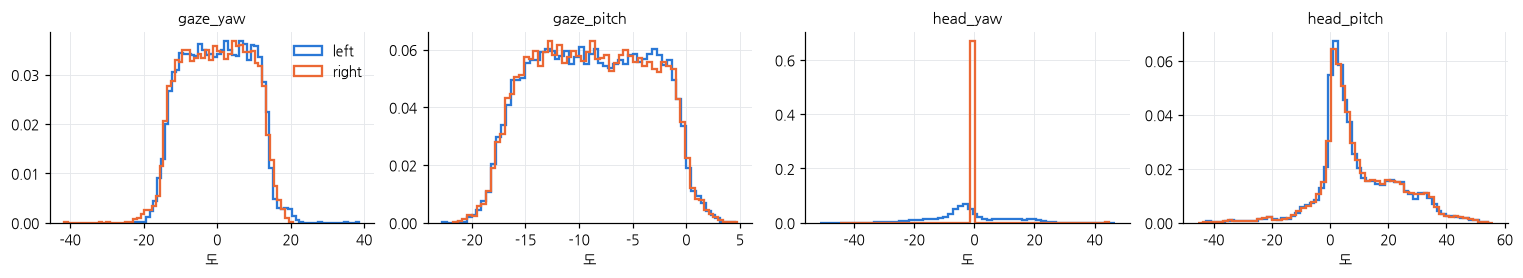

In [16]:
display(df.groupby("eye")[cols4 + ["distance_mm"]].agg(["mean", "std"]))
fig, axes = plt.subplots(1, 4, figsize=(14, 2.6))
for ax, c in zip(axes, cols4):
    for eye, color in [("left", viz.BLUE), ("right", viz.ORANGE)]:
        ax.hist(df.loc[df.eye == eye, c], bins=60, histtype="step", lw=1.5, color=color, label=eye, density=True)
    ax.set(title=c, xlabel="도")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

### 6.1 오른눈 head yaw가 0으로 몰리는 현상

위 표와 히스토그램에서 gaze 분포는 두 눈이 거의 같지만 **head yaw는 오른눈만 0° 근처에 몰려 있음** (표준편차 왼눈 11.61° vs 오른눈 1.59°). 4.2절 head pose 2D 분포의 yaw=0 세로줄, 7절 산점도의 세로줄도 같은 현상임.

원인은 전처리의 `head_flip`(GazeHub `HeadFlip`과 동일)으로 보임. 회전 행렬의 z축 x성분만 뒤집으면 회전 행렬이 아니게 되고, `cv2.Rodrigues`가 가장 가까운 회전으로 맞추는 과정에서 yaw 성분이 사라짐. 아래는 임의의 head 회전에 이 함수를 적용해 본 결과임 (데이터 없이 재현 가능).

In [ ]:
from preprocess.mpii_norm import head_flip, head_to_2d

rng_h = np.random.default_rng(0)
heads = rng_h.normal(0, 0.25, (2000, 3))      # 정면 근처의 무작위 head 회전 벡터
before = np.degrees([head_to_2d(h) for h in heads])
after = np.degrees([head_to_2d(head_flip(h)) for h in heads])
print(f"yaw 표준편차: flip 전 {before[:, 0].std():.2f}°  → flip 후 {after[:, 0].std():.2f}°")
print(f"pitch 상관 (flip 전 vs 후): {np.corrcoef(before[:, 1], after[:, 1])[0, 1]:.3f}")
print(f"좌우 반전이라면 기대하는 yaw = -yaw. 실제 flip 후 yaw의 |평균|: {np.abs(after[:, 0]).mean():.2f}°")

yaw 표준편차: flip 전 14.28°  → flip 후 0.95°
pitch 상관 (flip 전 vs 후): 0.997
좌우 반전이라면 기대하는 yaw = -yaw. 실제 flip 후 yaw의 |평균|: 0.02°


- 영향: 오른눈 샘플(전체의 절반)에서는 head yaw 입력이 사실상 상수가 됨. README에서 선형 모델이 head pose를 빼도 거의 같은 성능(7.27° vs 7.28°)을 보인 것과도 맞아떨어짐.
- 이 저장소에서는 수업 baseline과 같은 데이터로 비교하려고 전처리를 **고치지 않음**. 고친다면 오른눈의 head yaw를 −yaw로 바꾸는 방식(pitch 유지)이 자연스러움.

## 7. gaze와 head pose의 관계

정규화된 좌표계에서 gaze와 head pose의 상관. 상관이 크면 head pose만으로도 gaze를 어느 정도 예측할 수 있음.

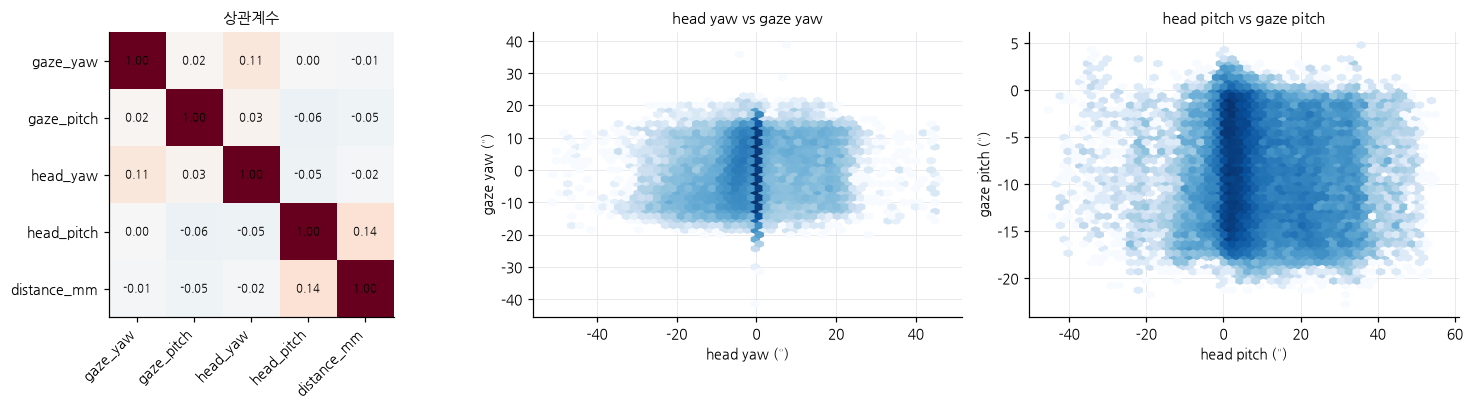

In [17]:
corr = df[cols4 + ["distance_mm"]].corr()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
im = axes[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
axes[0].set_yticks(range(len(corr)), corr.columns); axes[0].grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        axes[0].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
axes[0].set_title("상관계수")
for ax, k in zip(axes[1:], ["yaw", "pitch"]):
    ax.hexbin(df[f"head_{k}"], df[f"gaze_{k}"], gridsize=50, cmap="Blues", mincnt=1, bins="log")
    ax.set(title=f"head {k} vs gaze {k}", xlabel=f"head {k} (°)", ylabel=f"gaze {k} (°)")
plt.tight_layout(); plt.show()

## 8. 카메라–눈 거리

`Smat`의 세 번째 값은 600/d (d = 카메라에서 눈 중심까지 거리, mm). 정규화가 이 거리를 600mm로 맞춤.

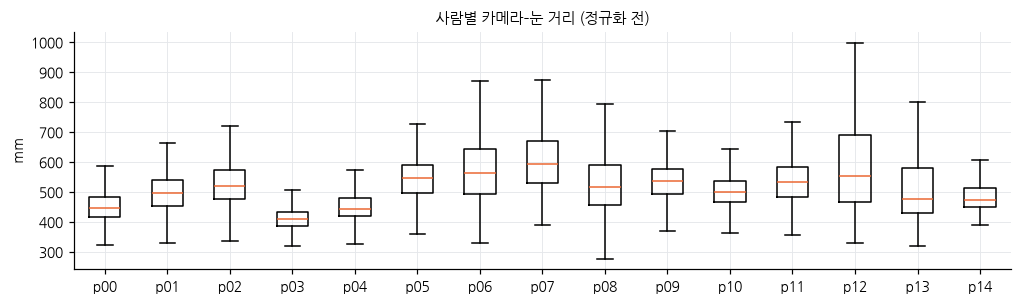

count    45000.00
mean       516.36
std         98.31
min        230.87
25%        445.53
50%        501.44
75%        569.98
max       1829.75
Name: distance_mm, dtype: float64

In [18]:
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.boxplot([df.loc[df.person == p, "distance_mm"] for p in PERSONS], tick_labels=PERSONS, showfliers=False,
           medianprops={"color": viz.ORANGE})
ax.set(title="사람별 카메라–눈 거리 (정규화 전)", ylabel="mm")
plt.show()
df["distance_mm"].describe()

## 9. 이미지와 gaze의 관계

### 9.1 gaze 구간별 평균 이미지

gaze yaw(가로)·pitch(세로)를 분위수로 5×5 구간으로 나누고 구간마다 평균 이미지를 그림. 홍채 위치가 gaze 방향에 따라 움직이면 CNN이 쓸 수 있는 신호가 있다는 뜻.

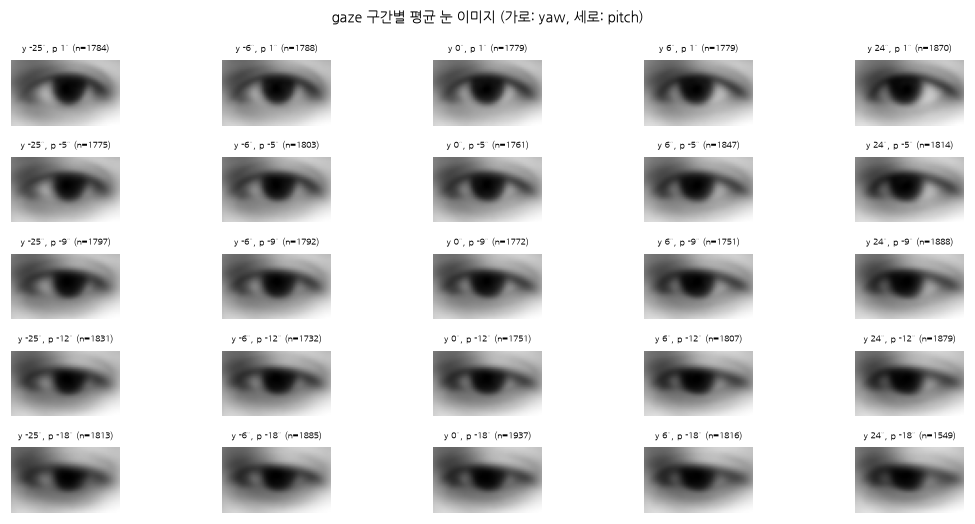

In [19]:
eye_flat = np.concatenate([data[p][0] for p in PERSONS])
g = np.degrees(np.concatenate([data[p][2] for p in PERSONS]))
nb = 5
yb = np.quantile(g[:, 0], np.linspace(0, 1, nb + 1)); pb = np.quantile(g[:, 1], np.linspace(0, 1, nb + 1))
yi = np.clip(np.digitize(g[:, 0], yb[1:-1]), 0, nb - 1); pi = np.clip(np.digitize(g[:, 1], pb[1:-1]), 0, nb - 1)
fig, axes = plt.subplots(nb, nb, figsize=(10, 4.8))
for r in range(nb):           # 위쪽 행 = pitch 큰 값
    for c in range(nb):
        sel = (pi == nb - 1 - r) & (yi == c)
        ax = axes[r, c]
        ax.imshow(eye_flat[sel].mean(0), cmap="gray"); ax.axis("off")
        ax.set_title(f"y {(yb[c]+yb[c+1])/2:.0f}°, p {(pb[nb-1-r]+pb[nb-r])/2:.0f}° (n={sel.sum()})", fontsize=6)
plt.suptitle("gaze 구간별 평균 눈 이미지 (가로: yaw, 세로: pitch)", fontsize=9)
plt.tight_layout(); plt.show()

### 9.2 픽셀–gaze 상관 지도

픽셀 값과 gaze yaw / pitch의 피어슨 상관. 빨강/파랑 영역이 gaze 정보를 많이 담은 위치.

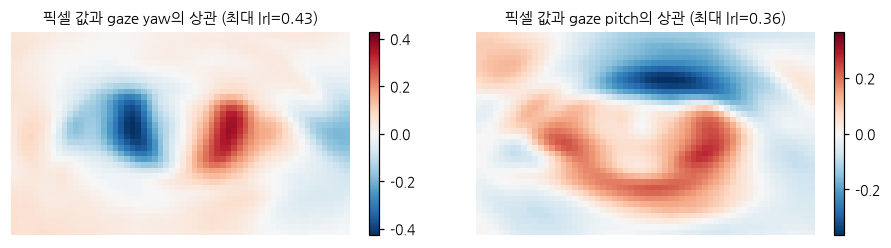

In [20]:
X = eye_flat.reshape(len(eye_flat), -1).astype(np.float32)
Xc = (X - X.mean(0)) / (X.std(0) + 1e-6)
fig, axes = plt.subplots(1, 2, figsize=(10, 2.4))
for ax, k, name in zip(axes, [0, 1], ["yaw", "pitch"]):
    y = (g[:, k] - g[:, k].mean()) / g[:, k].std()
    cmap = (Xc * y[:, None]).mean(0).reshape(36, 60)
    v = np.abs(cmap).max()
    im = ax.imshow(cmap, cmap="RdBu_r", vmin=-v, vmax=v); ax.axis("off")
    ax.set_title(f"픽셀 값과 gaze {name}의 상관 (최대 |r|={v:.2f})")
    plt.colorbar(im, ax=ax, fraction=0.03)
plt.show()
del X, Xc

## 10. 단순 기준선: 평균 gaze 예측

입력을 보지 않고 학습용 14명의 평균 gaze를 항상 내놓을 때의 각도 오차 (README의 하한선과 같음). 사람별 분포 차이가 오차에 그대로 드러남.

In [21]:
rows = []
for test in PERSONS:
    train_g = np.concatenate([data[p][2] for p in PERSONS if p != test])
    gt = data[test][2]
    err = angular_error(np.broadcast_to(train_g.mean(0), gt.shape), gt)
    rows.append({"person": test, "mean_pred_error": err.mean(), "gaze_spread_deg": np.degrees(gt.std(0)).mean()})
base = pd.DataFrame(rows).set_index("person")
print(f"평균 {base.mean_pred_error.mean():.2f}°")
base.T

평균 9.21°


person,p00,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p12,p13,p14
mean_pred_error,8.43,8.63,9.00,9.60,8.97,9.73,10.34,9.49,9.61,8.97,8.66,8.43,8.60,9.00,10.75
gaze_spread_deg,6.27,6.44,6.57,7.15,6.73,7.30,7.60,7.17,7.21,6.69,6.51,6.31,6.39,6.71,8.04


## 11. 정리

**데이터 구성**
- 15명 × 3,000개 = 45,000개, 사람마다 왼눈·오른눈 1,500개씩. 결측값 없음. p13만 같은 (프레임, 눈)이 4번 중복 (README와 일치)
- 원본 프레임은 213,658장인데 학습에는 사람당 1,498~2,929장만 쓰임. p12~p14는 원본이 1,500장 정도라 거의 전부를 쓰고, p00·p03은 10% 안팎만 씀
- 사람마다 기록한 day 수가 7~67일로 크게 다름

**이미지**
- histogram equalization 덕분에 픽셀 값이 0~255에 고르게 퍼져 있고(평균 129, 표준편차 74), 사람별 평균 밝기 차이도 작음 → 이미지 입력은 전체 평균·표준편차 하나로 표준화하면 충분
- 대신 눈 모양, 안경(p04, p09, p10 등), 흐림, 블록 노이즈 같은 **외형 차이**가 사람마다 뚜렷함 → 사람 단위 일반화가 핵심 난제

**라벨**
- gaze yaw 평균 0.0°(표준편차 8.7°), pitch 평균 −8.8°(5.2°). pitch는 거의 항상 음수(아래쪽)이고 분포가 화면 모양의 직사각형
- yaw와 pitch의 범위·중심이 달라 **정답을 축별로 표준화**해 학습함
- 사람별 gaze 분포는 비슷한 편(pitch 중앙값 약 −11°~−7°)이지만 head pose는 사람마다 크게 다름 (p07 head pitch 중앙값 약 32°, p11 head yaw 분산이 큼)
- gaze와 head pose의 상관은 작음(|r| ≤ 0.11) → head pose만으로는 gaze를 예측하기 어렵고, 이미지가 주된 정보원
- 오른눈 head yaw가 0으로 몰리는 전처리 현상이 있음 (6.1절)

**이미지와 gaze의 관계**
- gaze 구간별 평균 이미지에서 홍채가 yaw를 따라 좌우로, pitch를 따라 눈꺼풀과 함께 위아래로 움직임
- 픽셀–gaze 상관이 yaw는 홍채 양옆(|r| 최대 0.43), pitch는 위 눈꺼풀·아래쪽 경계(0.36)에 모여 있음 → 국소 패턴을 잡는 **CNN이 적합**

**평가 설계에 주는 의미**
- 입력을 보지 않는 평균 예측도 9.21°이고, gaze가 넓게 퍼진 p14(10.75°)가 가장 어려움
- 사람 사이 차이가 크므로 표준화 통계·검증·조기 종료 모두 **학습용 사람만으로** 처리하고, 검증 세트도 사람 단위로 떼어 냄 → `pipeline.ipynb`